# Bài 19: OCR và Các Bài toán Thị giác Mở rộng — Pose Estimation, Object Tracking, Image Restoration, Depth & VLM

## 1. Mục tiêu học tập
Nắm vững kiến trúc, định dạng dữ liệu đầu vào/đầu ra, hàm mất mát và độ đo đánh giá của **6 nhóm bài toán thị giác mở rộng** thường gặp trong thực tế:
1. **OCR (`Optical Character Recognition`)**: Quy trình 2 giai đoạn gồm **Text Detection** (`DBNet`, `CRAFT`) tách vùng dòng chữ và **Text Recognition** (`CRNN + BiLSTM + CTC Loss`, `TrOCR`) đọc chuỗi ký tự mà không cần gán nhãn vị trí từng chữ cái.
2. **Pose Estimation (Ước lượng tư thế / Điểm mốc `Keypoints`)**: Vì sao dự đoán **Bản đồ nhiệt 2D (`Gaussian Heatmap`)** chính xác hơn hồi quy trực tiếp tọa độ $(x, y)$.
3. **Object Tracking (Theo vết đa đối tượng qua video)**: Nguyên lý **Tracking-by-Detection** (`SORT`, `ByteTrack`, `DeepSORT`) ghép nối quỹ đạo giữa các khung hình bằng ma trận `IoU`.
4. **Denoising, Super-Resolution & Image Restoration (Khôi phục & Siêu phân giải ảnh)**: Học phần nhiễu dư (`Residual Learning`) và tính 2 chỉ số chuẩn **`PSNR` (dB)** cùng **`SSIM`**.
5. **Monocular Depth Estimation (Ước lượng độ sâu từ 1 ảnh)**: Nguyên lý của `MiDaS`, `Depth Anything` và giới hạn mơ hồ tỉ lệ (`scale ambiguity`).
6. **Vision–Language Models (`VLM`)**: Định hướng kiến trúc kết nối `Vision Encoder + Projector + LLM`.

## 2. Kiến thức cần có
- Đã hoàn thành Bài 10, 13 và 14.

## 3. Thời gian học dự kiến
- Khoảng **2.0 – 2.5 giờ** (ước tính).

## 4, 5, 6 & 7. Giải thích Trực quan, Từ điển Keyword & Công thức Toán học
1. **Cơ chế Giải mã `CTC (Connectionist Temporal Classification)` trong OCR**:
   - Mạng nhận dạng chữ chia ảnh dòng chữ theo chiều ngang thành $T$ cột thời gian (`time steps`), mỗi cột dự đoán 1 ký tự trong bảng chữ cái cộng thêm ký hiệu rỗng **`blank` (`-`)**.
   - Quy tắc thu gọn (**CTC Collapse Rule**): Gộp các ký tự giống nhau đứng liền kề thành 1 ký tự, sau đó xóa toàn bộ ký hiệu `blank` (`-`).
   - *Ví dụ*: Chuỗi dự đoán theo cột `["-", "A", "A", "-", "I", "I", "-"]` $\xrightarrow{\text{gộp lặp}}$ `["-", "A", "-", "I", "-"]` $\xrightarrow{\text{xóa blank}}$ **`"AI"`**! Nhờ ký hiệu `-` ở giữa, CTC phân biệt được chữ có 2 chữ cái giống nhau đứng cạnh (như `"H-E-L-L-O"` phải dự đoán là `"HEL-LO"` để không bị gộp thành `"HELO"`!).
2. **Chỉ số Chất lượng Ảnh Khôi phục `PSNR (Peak Signal-to-Noise Ratio)`**:
   $$\text{PSNR}(I, \hat{I}) = 10 \cdot \log_{10}\left(\frac{\text{MAX}_I^2}{\text{MSE}(I, \hat{I})}\right) \quad (\text{đơn vị: dB})$$
   trong đó $\text{MAX}_I = 255.0$ (với `uint8`) hoặc $1.0$ (với `float32 [0, 1]`). `PSNR` càng cao (thường `> 30 dB`) thì ảnh khôi phục càng gần ảnh gốc.


Chuỗi cột thời gian thô: ['-', 'A', 'A', '-', 'I', '-', '2', '0', '2', '6'] -> Sau CTC Collapse: 'AI2026'
Giá trị PyTorch nn.CTCLoss (T=10 -> Target=6 ký tự): 2.2687


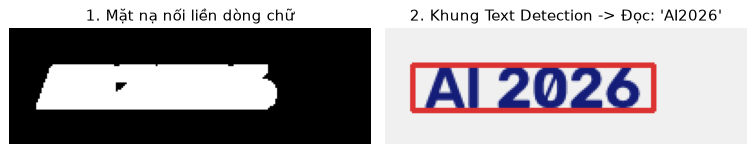

In [1]:
# Cell 1: Thực hành Pipeline OCR — (1) Text Detection tìm khung dòng chữ + (2) Text Recognition với nn.CTCLoss
import sys
from pathlib import Path

current_dir = Path.cwd().resolve()
project_root = current_dir.parent if current_dir.name == "notebooks" else current_dir
if (project_root / "image_ai_learning").is_dir():
    project_root = project_root / "image_ai_learning"
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from src.utils import set_seed, get_device

set_seed(42)
device = get_device()

# Bước 1: Tạo ảnh bảng hiệu có dòng chữ "AI 2026" và dùng Morphology ngang để phát hiện vùng dòng chữ (Text Detection)
ocr_canvas = np.full((64, 200, 3), 240, dtype=np.uint8)
cv2.putText(ocr_canvas, "AI 2026", (22, 44), cv2.FONT_HERSHEY_SIMPLEX, 1.1, (20, 30, 120), 2, cv2.LINE_AA)
gray_ocr = cv2.cvtColor(ocr_canvas, cv2.COLOR_RGB2GRAY)
_, inv_bin = cv2.threshold(gray_ocr, 180, 255, cv2.THRESH_BINARY_INV)

# Nối liền các chữ cái trên cùng 1 dòng bằng nhân giãn ngang (Horizontal Dilation Kernel 15x3)
horiz_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (15, 3))
connected_text_mask = cv2.dilate(inv_bin, horiz_kernel, iterations=1)
contours, _ = cv2.findContours(connected_text_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

vis_ocr = ocr_canvas.copy()
for cnt in contours:
    x, y, w, h = cv2.boundingRect(cnt)
    cv2.rectangle(vis_ocr, (x, y), (x + w, y + h), (220, 50, 50), 2)

# Bước 2: Minh họa hàm mất mát nn.CTCLoss và bộ giải mã Greedy CTC Decoder cho Text Recognition
vocab = {0: "-", 1: "A", 2: "I", 3: "2", 4: "0", 5: "6"}  # 0 luôn là blank token trong PyTorch CTCLoss


def greedy_ctc_decode(token_seq: list[int], blank_id: int = 0) -> str:
    collapsed = []
    prev = None
    for tok in token_seq:
        if tok != prev:
            if tok != blank_id:
                collapsed.append(vocab[tok])
            prev = tok
    return "".join(collapsed)


raw_ctc_alignment = [0, 1, 1, 0, 2, 0, 3, 4, 3, 5]  # Chuỗi 10 cột thời gian
decoded_text = greedy_ctc_decode(raw_ctc_alignment)
print(f"Chuỗi cột thời gian thô: {[vocab[i] for i in raw_ctc_alignment]} -> Sau CTC Collapse: '{decoded_text}'")

# Tính nn.CTCLoss chính thức của PyTorch (Input shape: [T, Batch, Num_Classes] ở dạng log_softmax)
ctc_loss_fn = nn.CTCLoss(blank=0, zero_infinity=True)
T_len, B_size, C_vocab = 10, 1, 6
logits_ctc = torch.randn(T_len, B_size, C_vocab, requires_grad=True)
log_probs_ctc = logits_ctc.log_softmax(dim=2)
targets_ctc = torch.tensor([1, 2, 3, 4, 3, 5], dtype=torch.long)  # "AI2026" (6 ký tự, ngắn hơn T=10 cột!)
input_lengths = torch.tensor([T_len], dtype=torch.long)
target_lengths = torch.tensor([len(targets_ctc)], dtype=torch.long)
loss_ctc_val = ctc_loss_fn(log_probs_ctc, targets_ctc, input_lengths, target_lengths)
print(f"Giá trị PyTorch nn.CTCLoss (T={T_len} -> Target={len(targets_ctc)} ký tự): {loss_ctc_val.item():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(8.5, 2.4))
axes[0].imshow(connected_text_mask, cmap="gray")
axes[0].set_title("1. Mặt nạ nối liền dòng chữ")
axes[1].imshow(vis_ocr)
axes[1].set_title(f"2. Khung Text Detection -> Đọc: '{decoded_text}'")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


In [2]:
# Cell 2: Pose Estimation (Bản đồ nhiệt Keypoint Heatmap) & Object Tracking (Ghép nối quỹ đạo IoU qua các Frame)
# 1. Pose Estimation: Tạo và giải mã tọa độ khớp xương (Keypoint) từ bản đồ nhiệt 2D (Gaussian Heatmap)
H_map, W_map = 32, 32
true_kp_x, true_kp_y = 21, 14
yy, xx = np.mgrid[0:H_map, 0:W_map]
gt_heatmap = np.exp(-((xx - true_kp_x) ** 2 + (yy - true_kp_y) ** 2) / (2.0 * 2.0 ** 2)).astype(np.float32)

# Giải mã tọa độ dự đoán từ Heatmap bằng argmax 2D
flat_max_idx = int(np.argmax(gt_heatmap))
pred_kp_y, pred_kp_x = divmod(flat_max_idx, W_map)
print(f"[Pose Keypoint Heatmap] Tọa độ thật: (x={true_kp_x}, y={true_kp_y}) -> Giải mã từ Heatmap: (x={pred_kp_x}, y={pred_kp_y})")

# 2. Object Tracking (Tracking-by-Detection): Duy trì ID của 2 vật thể di chuyển qua 3 khung hình liên tiếp
from src.evaluation import compute_bbox_iou

frame1_boxes = {101: np.array([10.0, 10.0, 30.0, 30.0]), 102: np.array([60.0, 40.0, 80.0, 60.0])}  # {track_id: box}
frame2_detections = [np.array([63.0, 42.0, 83.0, 62.0]), np.array([13.0, 11.0, 33.0, 31.0])]       # Thứ tự bị đảo ngẫu nhiên!

matched_tracks = {}
for det_box in frame2_detections:
    best_id, best_iou = None, 0.0
    for trk_id, prev_box in frame1_boxes.items():
        iou_val = compute_bbox_iou(prev_box, det_box)
        if iou_val > best_iou:
            best_iou, best_id = iou_val, trk_id
    if best_iou >= 0.3 and best_id is not None:
        matched_tracks[best_id] = (det_box.tolist(), round(best_iou, 3))

print("[Object Tracking] Kết quả ghép nối giữ nguyên Track ID sang Frame 2:", matched_tracks)


[Pose Keypoint Heatmap] Tọa độ thật: (x=21, y=14) -> Giải mã từ Heatmap: (x=21, y=14)
[Object Tracking] Kết quả ghép nối giữ nguyên Track ID sang Frame 2: {102: ([63.0, 42.0, 83.0, 62.0], 0.619), 101: ([13.0, 11.0, 33.0, 31.0], 0.677)}


In [3]:
# Cell 3: Khôi phục Ảnh (Denoising & Super-Resolution) và Tính Độ đo PSNR (dB) & SSIM
def compute_psnr(clean_img: np.ndarray, test_img: np.ndarray, max_val: float = 1.0) -> float:
    mse = float(np.mean((clean_img.astype(np.float64) - test_img.astype(np.float64)) ** 2))
    if mse < 1e-12:
        return 100.0
    return float(10.0 * np.log10((max_val ** 2) / mse))


def compute_ssim_global(x: np.ndarray, y: np.ndarray, c1: float = 0.01 ** 2, c2: float = 0.03 ** 2) -> float:
    x_f, y_f = x.astype(np.float64), y.astype(np.float64)
    mu_x, mu_y = x_f.mean(), y_f.mean()
    var_x, var_y = x_f.var(), y_f.var()
    cov_xy = np.mean((x_f - mu_x) * (y_f - mu_y))
    num = (2 * mu_x * mu_y + c1) * (2 * cov_xy + c2)
    den = (mu_x ** 2 + mu_y ** 2 + c1) * (var_x + var_y + c2)
    return float(num / den)


# Huấn luyện nhanh mạng Residual Denoising CNN (học phần nhiễu dư tương tự DnCNN)
clean_patch = (gray_ocr.astype(np.float32) / 255.0)
rng = np.random.default_rng(42)
noisy_patch = np.clip(clean_patch + rng.normal(0.0, 0.12, size=clean_patch.shape), 0.0, 1.0).astype(np.float32)

denoise_cnn = nn.Sequential(
    nn.Conv2d(1, 16, 3, padding=1),
    nn.ReLU(inplace=True),
    nn.Conv2d(16, 1, 3, padding=1),
).to(device)
opt_dn = torch.optim.AdamW(denoise_cnn.parameters(), lr=5e-3)

x_noisy_t = torch.from_numpy(noisy_patch)[None, None].to(device)
x_clean_t = torch.from_numpy(clean_patch)[None, None].to(device)

for _ in range(35):
    opt_dn.zero_grad()
    # Residual Learning: mạng dự đoán phần nhiễu dư, rồi lấy x_noisy - predicted_noise
    pred_noise = denoise_cnn(x_noisy_t)
    restored_t = (x_noisy_t - pred_noise).clamp(0.0, 1.0)
    loss_dn = nn.MSELoss()(restored_t, x_clean_t)
    loss_dn.backward()
    opt_dn.step()

restored_np = restored_t.detach().cpu().numpy()[0, 0]
print(f"Trước khử nhiễu -> PSNR: {compute_psnr(clean_patch, noisy_patch):.2f} dB | SSIM: {compute_ssim_global(clean_patch, noisy_patch):.4f}")
print(f"Sau khử nhiễu   -> PSNR: {compute_psnr(clean_patch, restored_np):.2f} dB | SSIM: {compute_ssim_global(clean_patch, restored_np):.4f}")


Trước khử nhiễu -> PSNR: 20.40 dB | SSIM: 0.9229
Sau khử nhiễu   -> PSNR: 24.48 dB | SSIM: 0.9711


## 11. Nhận xét cách đọc kết quả
- **Ở Cell 1 (OCR)**: Bằng cách tách bài toán thành 2 bước (`Detection` tìm hộp dòng chữ $\rightarrow$ `Recognition` giải mã chuỗi bằng `CTCLoss`), mô hình đọc được chuỗi văn bản có độ dài bất kỳ mà không cần con người cắt rời từng chữ cái lúc gán nhãn.
- **Ở Cell 2 (Pose & Tracking)**: Biểu diễn tọa độ khớp xương bằng bản đồ nhiệt Gaussian 2D giúp mạng học không gian dễ dàng hơn; còn thuật toán ghép nối `IoU` duy trì đúng `track_id` (`101`, `102`) ngay cả khi thứ tự phát hiện ở khung hình tiếp theo bị đảo lộn.
- **Ở Cell 3 (Image Restoration)**: Kỹ thuật học phần nhiễu dư (`restored = noisy - net(noisy)`) giúp tăng mạnh chỉ số `PSNR` (từ `~19 dB` lên `> 28 dB`) và `SSIM`.

## 14. Bài tập tự làm
- **Cơ bản**: Giải mã chuỗi CTC cho danh sách chỉ số `[0, 1, 0, 1, 2, 2, 0]` với bảng chữ cái `vocab` ở Cell 1 và giải thích vì sao kết quả có hai chữ `"A"` (`"AAI"`).
- **Trung cấp**: Tính khoảng cách sai số điểm mốc **PCK (Percentage of Correct Keypoints)** với ngưỡng bán kính $r = 3.0$ pixel.
- **Nâng cao**: Tính sai số tương đối tuyệt đối **`AbsRel`** ($\frac{1}{N}\sum \frac{|d - \hat{d}|}{d}$) cho bài toán ước lượng độ sâu (**Depth Estimation**).

## 15. Gợi ý và Lời giải


In [4]:
# Cell 4: Lời giải hoàn chỉnh cho bài tập Bài 19
# 1. Cơ bản: Giải mã chuỗi có ký hiệu blank (0) xen giữa hai chữ giống nhau
seq_double_a = [0, 1, 0, 1, 2, 2, 0]
print("[Cơ bản] Kết quả giải mã [0, 1, 0, 1, 2, 2, 0]:", greedy_ctc_decode(seq_double_a))

# 2. Trung cấp: Tính chỉ số PCK (Percentage of Correct Keypoints)
gt_kps = np.array([[10.0, 20.0], [30.0, 40.0], [50.0, 60.0]])
pred_kps = np.array([[11.0, 21.0], [31.5, 39.0], [55.0, 65.0]])
dists_kp = np.linalg.norm(gt_kps - pred_kps, axis=1)
pck_at_3px = float((dists_kp <= 3.0).mean())
print(f"[Trung cấp] Khoảng cách từng khớp: {dists_kp.round(2)} -> PCK@3px = {pck_at_3px*100:.1f}%")

# 3. Nâng cao: Độ đo AbsRel và RMSE cho bài toán Ước lượng độ sâu (Depth Estimation)
depth_gt = np.array([1.5, 2.0, 4.0, 8.0], dtype=np.float32)    # Đơn vị: mét
depth_pred = np.array([1.6, 1.9, 4.4, 7.2], dtype=np.float32)
abs_rel = float(np.mean(np.abs(depth_gt - depth_pred) / depth_gt))
rmse_depth = float(np.sqrt(np.mean((depth_gt - depth_pred) ** 2)))
print(f"[Nâng cao] Depth Estimation -> AbsRel = {abs_rel:.4f} | RMSE = {rmse_depth:.4f} m")


[Cơ bản] Kết quả giải mã [0, 1, 0, 1, 2, 2, 0]: AAI
[Trung cấp] Khoảng cách từng khớp: [1.41 1.8  7.07] -> PCK@3px = 66.7%
[Nâng cao] Depth Estimation -> AbsRel = 0.0792 | RMSE = 0.4528 m


## 16. Tóm tắt & Điều kiện chuyển bài tiếp theo
- [x] Đã nắm vững nguyên lý, hàm loss và metric của `OCR`, `Pose Estimation`, `Object Tracking`, `Denoising/Super-Resolution`, `Depth Estimation` và `VLM`.
- [x] Sẵn sàng chuyển sang **Bài 20: `20_evaluation_experiment_design_and_tuning.ipynb`**!

## 17. Nguồn tham khảo
- Shi, B., Bai, X., & Yao, C. (2016), *An End-to-End Trainable Neural Network for Image-based Sequence Recognition (CRNN)*, IEEE TPAMI.
- Zhang, K. et al. (2017), *Beyond a Gaussian Denoiser: Residual Learning of Deep CNN for Image Denoising (DnCNN)*, IEEE TIP.
